In [1]:
import os
import urllib.request
import ssl
import pandas as pd

# ۱. ساخت پوشه data اگر وجود نداشته باشد
os.makedirs('data', exist_ok=True)

# ۲. رد کردن بررسی گواهی SSL برای حل مشکل در مک
ssl_context = ssl._create_unverified_context()

# ۳. دانلود فایل با استفاده از کانتکست سفارشی
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
with urllib.request.urlopen(url, context=ssl_context) as response, open('data/churn.csv', 'wb') as out_file:
    out_file.write(response.read())

print("فایل با موفقیت دانلود شد!")

# ۴. بارگذاری داده‌ها و نمایش ابعاد
df = pd.read_csv('data/churn.csv')
print("Dataset Shape:", df.shape)
df.head()

فایل با موفقیت دانلود شد!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# ۱. بررسی اطلاعات کلی و نوع داده‌ها
print("--- اطلاعات کلی دیتاست ---")
df.info()

# ۲. بررسی مقادیر گمشده (Missing Values)
print("\n--- تعداد مقادیر گمشده در هر ستون ---")
print(df.isnull().sum())

# ۳. بررسی توزیع متغیر هدف (Customer Churn) به صورت درصدی
print("\n--- درصد ریزش مشتریان ---")
print(df['Churn'].value_counts(normalize=True) * 100)

--- اطلاعات کلی دیتاست ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non

In [3]:
# ۱. تبدیل مقادیر خالی به NaN و سپس تبدیل ستون به عدد (float)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# ۲. بررسی اینکه چند تا مقدار NaN داریم
print("تعداد مقادیر گمشده جدید در TotalCharges:", df['TotalCharges'].isnull().sum())

# ۳. پر کردن مقادیر گمشده با صفر (چون مشتریان جدید هستند و پرداختی نداشتند)
df['TotalCharges'].fillna(0, inplace=True)

# ۴. بررسی مجدد نوع داده‌ها
print("\nنوع داده TotalCharges بعد از اصلاح:", df['TotalCharges'].dtype)

تعداد مقادیر گمشده جدید در TotalCharges: 11

نوع داده TotalCharges بعد از اصلاح: float64


/var/folders/3p/j73bxpm57b98v516cb4j_ndc0000gn/T/ipykernel_21339/4247994944.py:8: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['TotalCharges'].fillna(0, inplace=True)


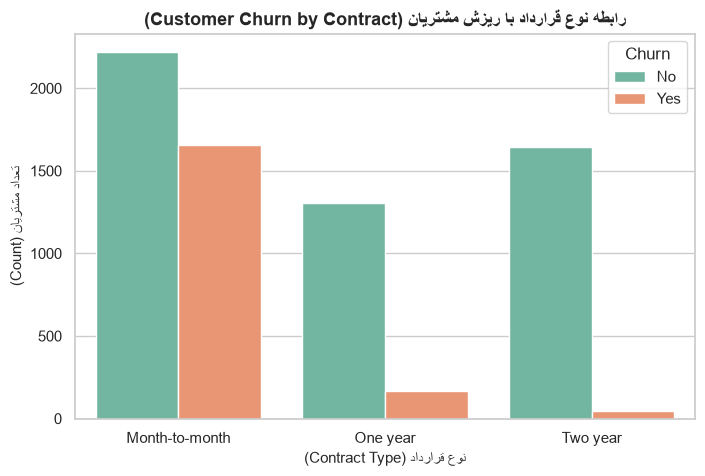

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیم ظاهر نمودارها
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# رسم نمودار تعداد مشتریان بر اساس نوع قرارداد و وضعیت ریزش
ax = sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')

# افزودن عنوان و برچسب‌ها
plt.title('رابطه نوع قرارداد با ریزش مشتریان (Customer Churn by Contract)', fontsize=13, fontweight='bold')
plt.xlabel('نوع قرارداد (Contract Type)', fontsize=11)
plt.ylabel('تعداد مشتریان (Count)', fontsize=11)

# نمایش نمودار
plt.show()

In [ ]:
# بررسی توزیع مدت حضور (tenure) بر اساس وضعیت ریزش
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set3')

plt.title('تأثیر مدت حضور (Tenure) بر ریزش مشتریان', fontsize=13, fontweight='bold')
plt.xlabel('وضعیت ریزش (Churn)', fontsize=11)
plt.ylabel('مدت حضور به ماه (Tenure)', fontsize=11)

plt.show()

In [ ]:
# محاسبه مجموع درآمد از دست رفته به ازای مشتریان ریزش‌کرده
churned_df = df[df['Churn'] == 'Yes']
total_monthly_loss = churned_df['MonthlyCharges'].sum()

print(f"تعداد کل مشتریان ریزش‌کرده: {len(churned_df)}")
print(f"مجموع درآمد ماهیانه از دست رفته به دلیل ریزش: ${total_monthly_loss:,.2f}")

In [ ]:
from sklearn.model_selection import train_test_split

# ۱. کپی دیتافریم برای مدل‌سازی
df_model = df.copy()

# حذف ستون customerID چون شناسه است و نقشی در پیش‌بینی ندارد
df_model.drop('customerID', axis=1, inplace=True)

# ۲. تبدیل متغیر هدف (Churn) به اعداد صفر و یک (۰ برای No و ۱ برای Yes)
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

# ۳. تبدیل تمام ستون‌های متنی (Categorical) به ستون‌های عددی (One-Hot Encoding)
df_model = pd.get_dummies(df_model, drop_first=True)

# ۴. جداسازی ویژگی‌ها (Features - X) و متغیر هدف (Target - y)
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

# ۵. تقسیم داده‌ها به بخش آموزش (۸۰٪) و تست (۲۰٪)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("ابعاد داده‌های آموزشی (X_train):", X_train.shape)
print("ابعاد داده‌های تستی (X_test):", X_test.shape)

In [ ]:
!pip install scikit-learn

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ۱. ساخت و آموزش مدل Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# ۲. پیش‌بینی روی داده‌های تست
y_pred = rf_model.predict(X_test)

# ۳. ارزیابی مدل
accuracy = accuracy_score(y_test, y_pred)
print(f"دقت مدل (Accuracy): {accuracy * 100:.2f}%\n")

print("گزارش ارزیابی مدل (Classification Report):")
print(classification_report(y_test, y_pred))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# ۱. آماده‌سازی و کدگذاری داده‌ها
df_model = df.copy()
df_model.drop('customerID', axis=1, inplace=True)
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})
df_model = pd.get_dummies(df_model, drop_first=True)

# ۲. جداسازی ویژگی‌ها و متغیر هدف
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

# ۳. تقسیم داده‌ها به آموزش و تست
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ۴. ساخت و آموزش مدل Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# ۵. پیش‌بینی و ارزیابی مدل
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"دقت مدل (Accuracy): {accuracy * 100:.2f}%\n")
print("گزارش ارزیابی مدل (Classification Report):")
print(classification_report(y_test, y_pred))

In [ ]:
# ۱. استخراج اهمیت ویژگی‌ها از مدل
importances = rf_model.feature_importances_
feature_names = X.columns

# ۲. ساخت یک دیتافریم برای مرتب‌سازی
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

# ۳. رسم نمودار ۱۰ ویژگی برتر
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('۱۰ عامل حیاتی و تأثیرگذار بر ریزش مشتریان از دید هوش مصنوعی', fontsize=13, fontweight='bold')
plt.xlabel('میزان اهمیت (Importance)', fontsize=11)
plt.ylabel('ویژگی‌ها (Features)', fontsize=11)
plt.show()

In [ ]:
import joblib

# ذخیره کردن مدل آموزش‌دیده در یک فایل
joblib.dump(rf_model, 'churn_random_forest_model.pkl')
print("مدل با موفقیت ذخیره شد!")